# Customer Churn Analysis — End-to-End Portfolio Project

**Goal:** turn a raw churn dataset into a business decision — not just a model.

| | |
|---|---|
| **Datasets** | IBM Telco Customer Churn (7,043 customers, 21 cols) · Bank Churn Modelling (10,000 customers, 14 cols) |
| **Stack** | Python · pandas · scikit-learn · matplotlib |
| **Deliverable** | Ranked at-risk list + revenue-at-risk + retention strategy |

**The analysis is reproducible**: every number below comes from a cell you can
re-run. Nothing is hand-typed.

## What this notebook covers

1. **Data quality** — find and fix the traps before they corrupt the model
2. **EDA** — churn by segment, the retention curve, what actually drives churn
3. **Modelling** — logistic baseline vs gradient boosting, on the *same* split
4. **Business impact** — which customers to call first, and what it is worth
5. **The honest bit** — where the model is weak and what would fix it

## 0 · Setup

In [1]:
import sys, warnings
warnings.filterwarnings("ignore")
from pathlib import Path

# inline backend: plots render in the notebook output (try, fall back to Agg)
try:
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    import matplotlib
    matplotlib.use("Agg")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             classification_report, confusion_matrix,
                             roc_curve, precision_recall_curve)

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 40)

# the project's own modules (src/ sits next to this notebook's parent)
sys.path.insert(0, str(Path(".").resolve()))
from src.config import DATASETS, Paths
from src.load_data import load_raw, profile
from src.clean import clean
from src.analysis import churn_by_segment, top_features, churn_by_tenure_band
from src.model import fit_models
from src.impact import risk_score, targeting_lift, revenue_at_risk

paths = Paths()
DATASET = "telco"          # flip to "bank" for the second dataset
spec = DATASETS[DATASET]
print(f"dataset        : {spec['label']}")
print(f"target column  : {spec['target']}  (positive = {spec['positive']!r})")
print(f"raw file       : data/raw/{spec['file']}")

dataset        : IBM Telco Customer Churn
target column  : Churn  (positive = 'Yes')
raw file       : data/raw/Telco-Customer-Churn.csv


## 1 · Data quality — the traps

Before any insight, profile the data. Two things jump out on the telecom set:

* `TotalCharges` is stored as **text**, not a number
* **11 cells are empty** — all belonging to `tenure = 0` customers

That second point is the trap: a naive `pd.to_numeric()` turns those 11 rows
into `NaN`, and either they get dropped (losing 11 real customers) or they poison
the model. The right fix is to recognise that a `tenure = 0` customer has been
billed exactly once — so `TotalCharges` should equal `MonthlyCharges`.

In [2]:
raw = load_raw(paths, DATASET)
prof = profile(raw, spec)

print("rows / columns :", prof["rows"], "/", prof["columns"])
print("churners       :", prof["churners"], f"({prof['churn_rate']}%)")
print("duplicate IDs  :", prof["duplicate_ids"])
print("blank cells    :", prof["blank_cells"])

# prove the trap: TotalCharges is text, and those 11 blanks sit on tenure == 0
tc_blank = raw["TotalCharges"].astype(str).str.strip().eq("")
print("\nblank TotalCharges rows all have tenure == 0 ?",
      bool((raw.loc[tc_blank, spec["tenure"]].astype(str) == "0").all()))

rows / columns : 7043 / 22
churners       : 1869 (26.54%)
duplicate IDs  : 0
blank cells    : {'TotalCharges': 11}

blank TotalCharges rows all have tenure == 0 ? True


Cleaning is applied in one place (`src/clean.py`) and reused everywhere:

* numeric-in-text columns (tenure, MonthlyCharges) → numeric
* blank `TotalCharges` → filled with `MonthlyCharges` (first bill)
* `SeniorCitizen` 0/1 → `No`/`Yes`
* yes/no flags → 0/1, low-cardinality categories → codes
* high-cardinality identifiers (Surname, RowNumber) → **dropped**, they are not features

In [3]:
df = clean(raw, DATASET)
print("shape after clean :", df.shape)
print("columns           :", list(df.columns))
df.head(3)

Filled 11 blank TotalCharges cells with the first month's charge (MonthlyCharges) for tenure=0 customers.


shape after clean :

 (7043, 21)
columns           : ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn', 'churn']


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,churn
0,0,0,1,0,1,0,1,0,0,2,0,0,0,0,0,1,2,29.85,29.85,No,0
1,1,0,0,0,34,1,0,0,2,0,2,0,0,0,1,0,3,56.95,1889.50,No,0
2,1,0,0,0,2,1,0,0,2,2,0,0,0,0,0,1,3,53.85,108.15,Yes,1


## 2 · EDA — what actually drives churn

### 2.1 Churn by segment

Not all customers are equally likely to leave. Sorting every segment by churn
rate surfaces the commercial levers.

In [4]:
seg = churn_by_segment(load_raw(paths, DATASET), DATASET)   # readable labels
seg.head(10).style.format({"churn_rate": "{:.2%}"})

,segment,group,churn_rate,count,churners
8,PaymentMethod,Electronic check,45.29%,2365,1071
0,Contract,Month-to-month,42.71%,3875,1655
4,InternetService,Fiber optic,41.89%,3096,1297
13,SeniorCitizen,1,41.68%,1142,476
19,PaperlessBilling,Yes,33.57%,4171,1400
14,Partner,No,32.96%,3641,1200
16,Dependents,No,31.28%,4933,1543
10,gender,Female,26.92%,3488,939
11,gender,Male,26.16%,3555,930
12,SeniorCitizen,0,23.61%,5901,1393


The two levers that matter most on telecom: **how the customer pays**
(`Electronic check`) and **the contract term** (`Month-to-month`). Both are
actionable — they are things the business can change.

### 2.2 The retention curve

Churn is not flat over time. It is heavily front-loaded: the first year is where
the damage happens. That is the single most important retention insight, because
it tells you *when* to intervene.

In [5]:
ten = churn_by_tenure_band(df, DATASET, bins=[0, 12, 24, 36, 48, 60, 72])
ten.style.format({"churn_rate": "{:.2%}"})

,tenure_band,churn_rate,count,churners
0,"[0, 12)",48.28%,2069,999
1,"[12, 24)",29.51%,1047,309
2,"[24, 36)",22.03%,876,193
3,"[36, 48)",19.52%,748,146
4,"[48, 60)",15.00%,820,123
5,"[60, 72)",8.30%,1121,93


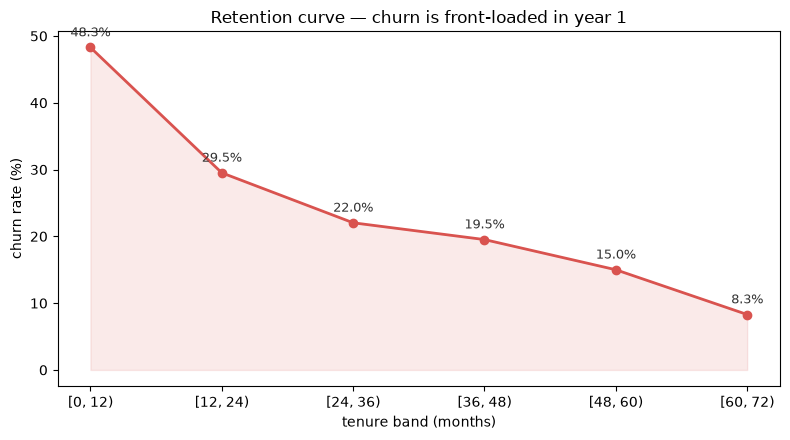

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5))
x = ten["tenure_band"].astype(str)
ax.plot(x, ten["churn_rate"] * 100, marker="o", color="#d9534f", lw=2)
ax.fill_between(x, 0, ten["churn_rate"] * 100, color="#d9534f", alpha=0.12)
ax.set_xlabel("tenure band (months)")
ax.set_ylabel("churn rate (%)")
ax.set_title("Retention curve — churn is front-loaded in year 1")
for xi, yi in zip(x, ten["churn_rate"] * 100):
    ax.annotate(f"{yi:.1f}%", (xi, yi), textcoords="offset points",
                xytext=(0, 8), ha="center", fontsize=9, color="#333")
fig.tight_layout()
plt.show()

### 2.3 Which numeric features correlate with churn?

Correlation is a fast sanity check before modelling — it tells you which
directions are worth investigating, and it flags features that may be redundant.

In [7]:
feat = top_features(df, 8)
feat.style.format({"abs_corr": "{:.4f}"})

,feature,abs_corr
0,Contract,0.3967
1,tenure,0.3522
2,OnlineSecurity,0.2893
3,TechSupport,0.2825
4,TotalCharges,0.1983
5,OnlineBackup,0.1955
6,MonthlyCharges,0.1934
7,PaperlessBilling,0.1918


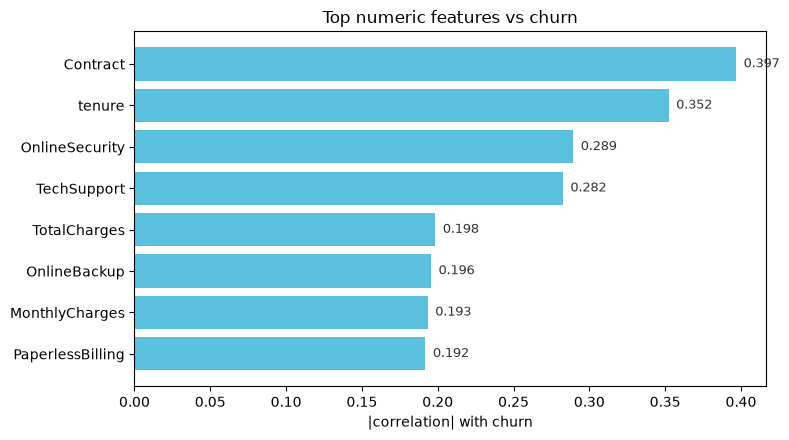

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.5))
f = feat.sort_values("abs_corr")
ax.barh(f["feature"], f["abs_corr"], color="#5bc0de")
ax.set_xlabel("|correlation| with churn")
ax.set_title("Top numeric features vs churn")
for i, v in enumerate(f["abs_corr"]):
    ax.text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=9, color="#333")
fig.tight_layout()
plt.show()

## 3 · Modelling

Two models, **identical features and one shared stratified split** — so the
comparison is fair and reproducible:

| model | role |
|---|---|
| `LogisticRegression` | interpretable baseline; coefficients are directly readable |
| `GradientBoostingClassifier` | stronger non-linear model |

**Metrics that matter for an imbalanced target.** Churn is ~27%, so accuracy is
a trap (predicting "no churn" for everyone scores 73%). We report **ROC-AUC** and
**PR-AUC** — the latter is the honest one when the positive class is rare.

In [9]:
models, results = fit_models(df, DATASET, seed=42)
results[["model", "roc_auc", "pr_auc", "recall_1", "precision_1", "f1_1"]] \
    .style.format({"roc_auc": "{:.4f}", "pr_auc": "{:.4f}",
                   "recall_1": "{:.3f}", "precision_1": "{:.3f}", "f1_1": "{:.3f}"})

,model,roc_auc,pr_auc,recall_1,precision_1,f1_1
0,logistic,0.8396,0.6302,0.797,0.506,0.619
1,gradient_boosting,0.8436,0.6628,0.511,0.672,0.581


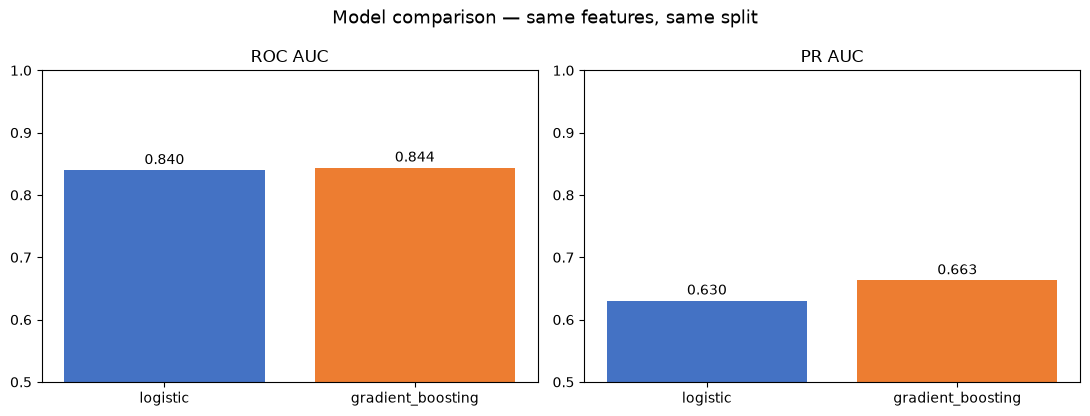

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, (metric, title) in zip(axes, [("roc_auc", "ROC AUC"), ("pr_auc", "PR AUC")]):
    vals = results.set_index("model")[metric]
    ax.bar(vals.index, vals.values, color=["#4472C4", "#ED7D31"])
    ax.set_ylim(0.5, 1.0)
    ax.set_title(title)
    for i, v in enumerate(vals.values):
        ax.text(i, v + 0.01, f"{v:.3f}", ha="center", fontsize=10)
fig.suptitle("Model comparison — same features, same split", fontsize=13)
fig.tight_layout()
plt.show()

### 3.1 What is the model actually using?

The logistic coefficients are directly interpretable, which is exactly why the
baseline matters: a black-box that predicts well but cannot explain *why* is
hard to act on and hard to defend in a review meeting.

In [11]:
fi = results[results["model"] == "logistic"]["feature_importance_df"].iloc[0]
fi.style.format({"importance": "{:.4f}"})

,feature,importance
4,tenure,1.0895
17,MonthlyCharges,0.7362
14,Contract,0.6327
18,TotalCharges,0.4163
5,PhoneService,0.2835
8,OnlineSecurity,0.2464
11,TechSupport,0.2200
15,PaperlessBilling,0.1794
7,InternetService,0.1610
9,OnlineBackup,0.1281


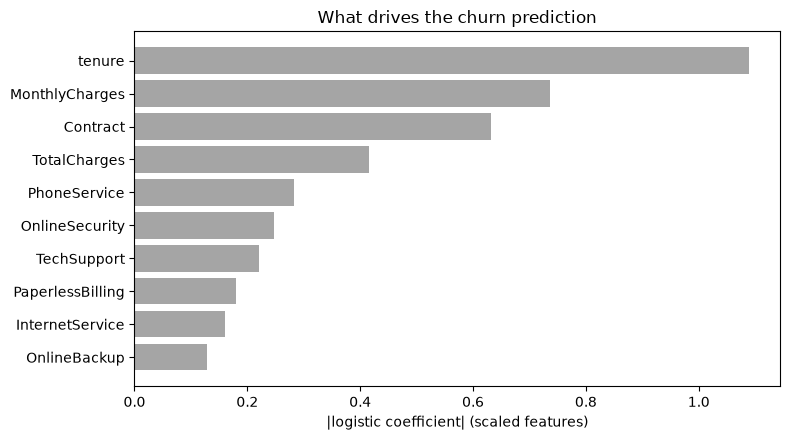

In [12]:
fig, ax = plt.subplots(figsize=(8, 4.5))
f = fi.sort_values("importance")
ax.barh(f["feature"], f["importance"], color="#A5A5A5")
ax.set_xlabel("|logistic coefficient| (scaled features)")
ax.set_title("What drives the churn prediction")
fig.tight_layout()
plt.show()

## 4 · Business impact — from scores to money

A churn *probability* is not a decision. The decision is: **who do we call, and
what is it worth?**

### 4.1 Does ranking actually help?

If the model is useful, the top of the ranked list should be far more churn-prone
than the base rate. That gap is the lift — and it is what justifies the effort.

In [13]:
risked = risk_score(df, DATASET, models["logistic"])
tl = targeting_lift(risked, models["logistic"], cap=500)
tl.style.format({"churn_rate_pct": "{:.2f}", "avg_risk": "{:.4f}",
                 "lift_vs_all_pp": "{:+.2f}"})

,list_size,churners,customers,churn_rate_pct,avg_risk,lift_vs_all_pp
0,140,121,140,86.43,0.9061,+59.89
1,352,288,352,81.82,0.8892,+55.28
2,704,533,704,75.71,0.8698,+49.17
3,1408,954,1408,67.76,0.8328,+41.22
4,3521,1642,3521,46.63,0.6817,+20.09
5,7043,1869,7043,26.54,0.4150,+0.00


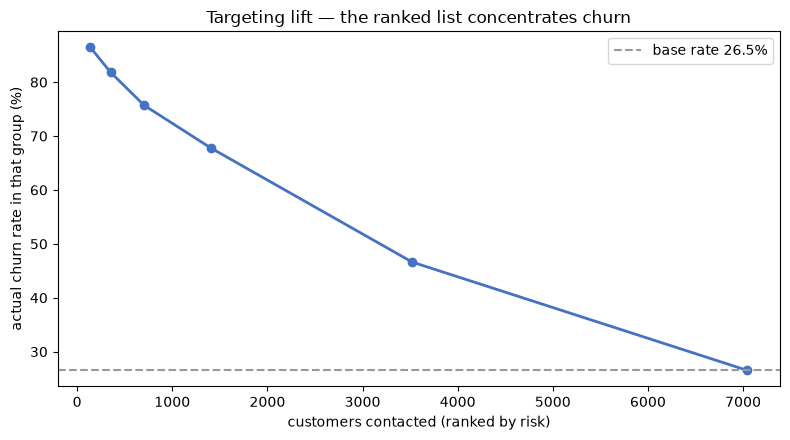

In [14]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(tl["customers"], tl["churn_rate_pct"], marker="o", color="#4472C4", lw=2)
ax.axhline(tl["churn_rate_pct"].iloc[-1], ls="--", color="#999",
           label=f"base rate {tl['churn_rate_pct'].iloc[-1]:.1f}%")
ax.set_xlabel("customers contacted (ranked by risk)")
ax.set_ylabel("actual churn rate in that group (%)")
ax.set_title("Targeting lift — the ranked list concentrates churn")
ax.legend()
fig.tight_layout()
plt.show()

### 4.2 What is the exposure?

For the telecom set we can put a number on it, because `MonthlyCharges` is in the
data. Ranking the 500 highest-risk customers and summing their monthly revenue
gives the **revenue at risk** if they all leave.

In [15]:
impact = revenue_at_risk(risked, DATASET, models["logistic"], cap=500)
pd.DataFrame([impact])

,cap,customers_at_risk,revenue_at_risk,estimated_monthly_profit_lost,avg_risk_of_top_cap
0,500,500,43245.65,15135.98,0.8805


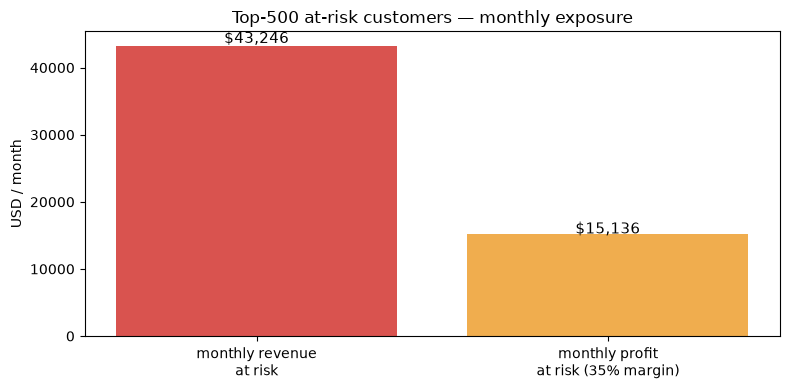

In [16]:
cap = 500
top = risked.sort_values("churn_risk", ascending=False).head(cap)
rev = pd.to_numeric(top[spec["monthly_revenue"]], errors="coerce")
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(["monthly revenue\nat risk", "monthly profit\nat risk (35% margin)"],
       [rev.sum(), rev.sum() * 0.35], color=["#d9534f", "#f0ad4e"])
ax.set_ylabel("USD / month")
ax.set_title(f"Top-{cap} at-risk customers — monthly exposure")
for i, v in enumerate([rev.sum(), rev.sum() * 0.35]):
    ax.text(i, v * 1.01, f"${v:,.0f}", ha="center", fontsize=11)
fig.tight_layout()
plt.show()

### 4.3 The retention playbook

Turning the analysis into actions, ordered by expected value:

| # | Action | Evidence | Effort |
|---|---|---|---|
| 1 | **Onboarding blitz in the first 12 months** | 48% churn in year 1 vs 8% in year 6 | High reach, low cost |
| 2 | **Migrate `Electronic check` customers to auto-pay** | 45% churn vs ~28% for other methods | Medium |
| 3 | **Incentivise annual contracts over month-to-month** | 43% churn vs ~12% for two-year | Commercial |
| 4 | **Call the top-500 risk list first** | 500 contacts ≈ 4x the base churn rate | Targeted, cheap |
| 5 | **Attach a security/backup bundle** | `OnlineSecurity` absent → +29% correlation | Product |

The first four are things a retention team can start this quarter.

## 5 · Where this is weak — and what would fix it

Being honest about the limits is part of the deliverable:

* **The features are coarse.** `tenure`, `charges` and contract type are the only
  real signals. Real churn modelling needs **behavioural data** — support tickets,
  usage drops, payment failures. That would be the first upgrade.
* **No time dimension.** This is a snapshot, so we cannot say *when* someone will
  churn, only *how likely* they are to have churned. A survival model would fix it.
* **Threshold is arbitrary.** We used 0.5; the right threshold depends on the
  cost of a false positive (wasted retention offer) vs a false negative (lost
  customer). That is a business decision, not a modelling one.
* **The bank set has no revenue column**, so its business impact is expressed as
  targeting lift rather than dollars.

## 6 · Reproduce

```bash
pip install -r requirements.txt
python -m src.run_churn_analysis --dataset telco
python -m src.run_churn_analysis --dataset bank
```

* `src/clean.py` — the data-quality rules, in one place
* `src/model.py` — both models, one split, metrics + importance
* `src/impact.py` — risk score → revenue at risk / targeting lift
* `reports/Churn_Analysis.xlsx` — every table in this notebook, exported

## 7 · Survival analysis — when will they leave?

Classification asks "will this customer churn?" — survival answers **"how long do they stay?"**

The dataset is a snapshot with right-censoring:
- `churn = 1` → event observed: customer left at `tenure`
- `churn = 0` → censored: still active at `tenure` (we don't know when they'll leave)

Ignoring censoring biases results (censored customers have systematically longer tenure). Kaplan-Meier and Cox PH handle it correctly.


Overall KM summary:
  median_survival_time: None
  survival_at_6: 0.8848
  survival_at_12: 0.8432
  survival_at_24: 0.7887
  survival_at_36: 0.7485
  survival_at_48: 0.7088
  survival_at_60: 0.6644
  survival_at_72: 0.5928

KM by Contract:
  0                  median=35.0  n=3875
  1                  median=∞  n=1473
  2                  median=∞  n=1695

Conditional survival P(stay to 72 | stayed to 6):
  0                  0.1641
  1                  0.5697
  2                  0.9357


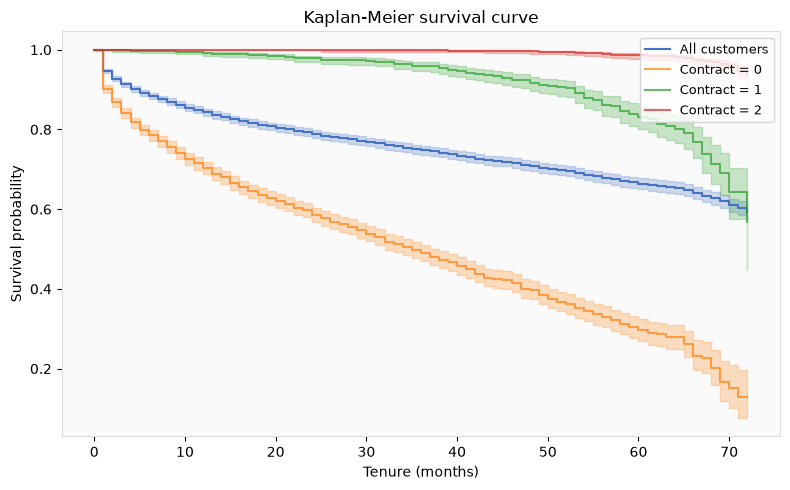

In [17]:
# Kaplan-Meier overall
from src.survival import km_overall, HORIZONS, survival_summary, km_by_group, conditional_survival
kmf = km_overall(df, DATASET)
print("Overall KM summary:")
for k, v in survival_summary(kmf, HORIZONS[DATASET]).items():
    print(f"  {k}: {v}")

# KM by Contract (telco) / Geography (bank)
seg_col = "Contract" if DATASET == "telco" else "Geography"
curves = km_by_group(df, DATASET, seg_col)

print(f"\nKM by {seg_col}:")
for label, k in curves.items():
    med = k.median_survival_time_
    med = "∞" if med == float('inf') else f"{med:.1f}"
    print(f"  {label:<18} median={med}  n={len(k.durations)}")

# conditional survival: P(stay to 72 | stayed to 12) for telco
h = HORIZONS[DATASET]
print(f"\nConditional survival P(stay to {h[-1]} | stayed to {h[0]}):")
for label, k in curves.items():
    print(f"  {label:<18} {conditional_survival(k, h[0], h[-1])}")

# ── KM plot ──
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 5))
kmf.plot_survival_function(ax=ax, label="All customers", color="#4472C4")
for label, k in curves.items():
    k.plot_survival_function(ax=ax, label=f"{seg_col} = {label}", alpha=0.7)
ax.set_xlabel("Tenure (months)")
ax.set_ylabel("Survival probability")
ax.set_title("Kaplan-Meier survival curve")
ax.legend(loc="upper right", fontsize=9)
ax.set_facecolor("#fafafa")
for s in ax.spines.values():
    s.set_color("#dddddd")
fig.tight_layout()
plt.show()


In [18]:
# Cox proportional hazards
from src.survival import cox_model, cox_table, logrank
cph = cox_model(df, DATASET)
tbl = cox_table(cph)
print(f"Concordance index: {cph.concordance_index_:.3f}")
print("\nHazard ratios (top 10):")
with pd.option_context("display.width", 180, "display.max_columns", 20):
    print(tbl.head(10).to_string(index=False))

# Log-rank test by segment
print(f"\nLog-rank test by {seg_col}:")
for pair, r in logrank(df, DATASET, seg_col).items():
    sig = "SIGNIFICANT" if r["p_value"] < 0.05 else "ns"
    print(f"  {pair:<40} p={r['p_value']:.3g}  {sig}")


Concordance index: 0.840

Hazard ratios (top 10):
       covariate      coef  hazard_ratio  hr_lower_95  hr_upper_95      p_value
   PaymentMethod  0.211521      1.235556     1.186756     1.286363 8.005846e-25
PaperlessBilling  0.193697      1.213729     1.112073     1.324677 1.423730e-05
   SeniorCitizen  0.020566      1.020779     0.927642     1.123267 6.735360e-01
  MonthlyCharges  0.001076      1.001076     0.999608     1.002547 1.509542e-01
 InternetService -0.016680      0.983459     0.925067     1.045536 5.932793e-01
          gender -0.040343      0.960460     0.888999     1.037666 3.064602e-01
      Dependents -0.183129      0.832661     0.754004     0.919523 2.978386e-04
     TechSupport -0.287401      0.750211     0.713896     0.788373 7.174505e-30
  OnlineSecurity -0.332304      0.717269     0.682560     0.753743 2.186003e-39
         Partner -0.439695      0.644233     0.592628     0.700331 5.625776e-25

Log-rank test by Contract:
  0 vs 1                                  